# Rust backend of radiopyo

radiopyo can hand a simulation to radkin, a Rust port of the same model, through the optional `radiopyo-rs` extension (`rust/` in this repository). The configuration and the state of a `UnitCell` cross the boundary: radkin builds the same system, solves it with its own LSODA and returns an `ODEResult`, so plotting, `to_pandas`, `reconstruct_reactions` and HDF5 storage work as usual.

Install (once, in the radiobio env): a release wheel (`pip install radiopyo_rs-<version>-cp311-abi3-<platform>.whl`), or from source with a Rust toolchain: `pip install ./rust`.

## Module imports

In [1]:
# External modules (to "pip install")
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -> RadioBio module
import radiopyo as rp
from radiopyo.physics.beam import ConstantBeam, PulsedBeam

# Quieter output for this notebook
import logging
logging.getLogger("radiopyo").setLevel(logging.WARNING)

### Is the extension installed?

In [3]:
print("Rust backend available:", rp.rust.is_available())

Rust backend available: True


## One run, both backends

`backend="rust"` is the only change. Before solving, a parity guard compares the species, the reactions and their k values and G-values built by radkin with Python's (rtol 1e-12) and raises `ParityError` on a mismatch.

In [4]:
uc = rp.UnitCell.from_toml(rp.LABARBE_CONFIG_FILE)
uc.set_beam(ConstantBeam(dose_rate=0.1, max_dose=10.0), LET=0.201)
t_span = (0.0, 100.0)

t0 = time.perf_counter()
res_py = uc.run(t_span=t_span)
dt_py = time.perf_counter() - t0

t0 = time.perf_counter()
res_rs = uc.run(t_span=t_span, backend="rust")
dt_rs = time.perf_counter() - t0
print(f"Python: {dt_py:.2f} s, Rust: {dt_rs:.2f} s")

Python: 0.13 s, Rust: 0.02 s


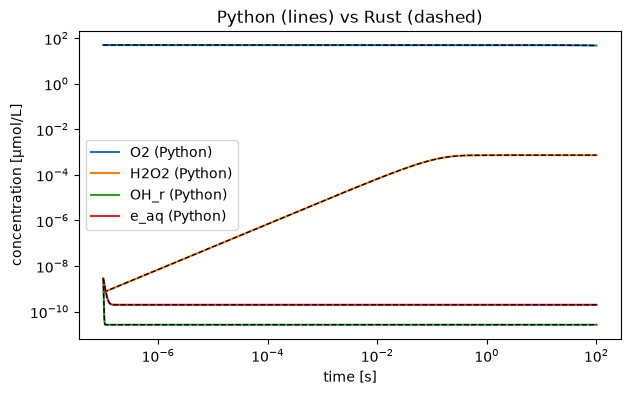

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for label in ["O2", "H2O2", "OH_r", "e_aq"]:
    idx = uc.env.species[label].index
    ax.loglog(res_py.t, res_py.y[idx], label=f"{label} (Python)")
    ax.loglog(res_rs.t, res_rs.y[idx], "--", color="k", lw=1)
ax.set_xlabel("time [s]")
ax.set_ylabel("concentration [µmol/L]")
ax.set_title("Python (lines) vs Rust (dashed)")
ax.legend()
plt.show()

Both codes take their own steps, so they agree to the solver tolerance; trace species (below 1e-6 µmol/L, near the absolute tolerance) differ more in relative terms.

In [6]:
ref = res_py.final_cc
big = np.abs(ref) > 1e-6
rel = np.abs(res_rs.final_cc - ref)[big] / np.abs(ref[big])
print(f"max relative difference of the final state ({big.sum()} species > 1e-6 µmol/L): {rel.max():.1e}")

max relative difference of the final state (14 species > 1e-6 µmol/L): 1.8e-08


## Chunked pulsed run

`prepare_chunked_run(...).run(backend="rust")` (and the same for `prepare_single_pulse`): radkin cuts the chunks itself with the same options.

In [7]:
uc_p = rp.UnitCell.from_toml(rp.LABARBE_CONFIG_FILE)
uc_p.set_beam(PulsedBeam.from_dose_rate_peak(1e6, 1e-3, 1e-5, max_dose=100.0), LET=0.201)

t0 = time.perf_counter()
pulsed_py = uc_p.prepare_chunked_run(t_span=(0.0, 1e-2)).run()
dt_chunk_py = time.perf_counter() - t0

t0 = time.perf_counter()
pulsed_rs = uc_p.prepare_chunked_run(t_span=(0.0, 1e-2)).run(backend="rust")
dt_chunk_rs = time.perf_counter() - t0
print(f"Python: {dt_chunk_py:.2f} s, Rust: {dt_chunk_rs:.2f} s")

  0%|          | 0/20 [00:00<?, ?it/s]

Python: 1.44 s, Rust: 0.05 s


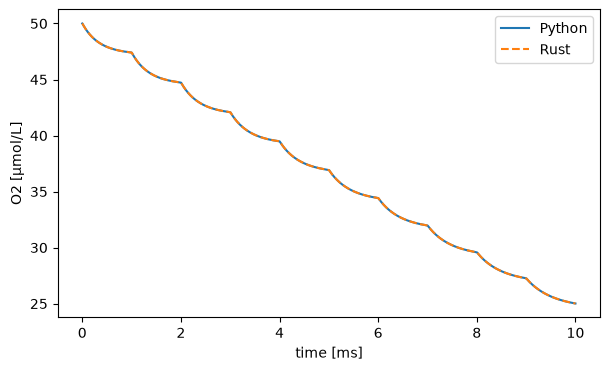

In [8]:
idx = uc_p.env.species["O2"].index
plt.figure(figsize=(7, 4))
plt.plot(pulsed_py.t * 1e3, pulsed_py.y[idx], label="Python")
plt.plot(pulsed_rs.t * 1e3, pulsed_rs.y[idx], "--", label="Rust")
plt.xlabel("time [ms]")
plt.ylabel("O2 [µmol/L]")
plt.legend()
plt.show()

## Parameter sweep with `run_batch`

`rp.rust.run_batch(cells, t_span, mode=...)` runs a list of cells in parallel (all cores by default, `n_threads=` to limit). Every cell keeps its own beam, LET, temperature... By default the first error is raised once every cell has finished; with `return_exceptions=True` each error takes the place of its cell's result.

In [9]:
lets = [0.201, 1.0, 5.0, 20.0, 60.0]
cells = []
for let in lets:
    cell = copy.deepcopy(uc_p)
    cell.set_beam(PulsedBeam.from_dose_rate_peak(1e6, 1e-3, 1e-5, max_dose=100.0), LET=let)
    cells.append(cell)

t0 = time.perf_counter()
sweep = rp.rust.run_batch(cells, (0.0, 1e-2), mode="chunked")
dt_batch = time.perf_counter() - t0
print(f"{len(cells)} runs in {dt_batch:.2f} s")

5 runs in 0.18 s


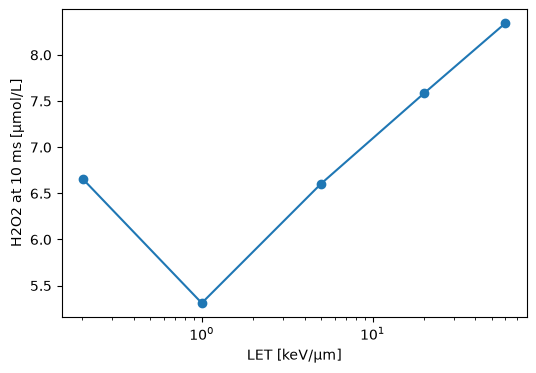

In [10]:
idx = uc_p.env.species["H2O2"].index
final_h2o2 = [res.y[idx, -1] for res in sweep]
plt.figure(figsize=(6, 4))
plt.semilogx(lets, final_h2o2, "o-")
plt.xlabel("LET [keV/µm]")
plt.ylabel("H2O2 at 10 ms [µmol/L]")
plt.show()

## Timing

In [11]:
pd.DataFrame(
    {
        "Python [s]": [dt_py, dt_chunk_py, np.nan],
        "Rust [s]": [dt_rs, dt_chunk_rs, dt_batch],
    },
    index=["constant beam run", "pulsed chunked run", f"run_batch ({len(cells)} LETs)"],
).round(3)

,Python [s],Rust [s]
constant beam run,0.126,0.023
pulsed chunked run,1.443,0.054
run_batch (5 LETs),NaN,0.175


## Limits

- LSODA only (`method` must be `"LSODA"`).
- Only cells built from a config (`UnitCell.from_toml` / `from_config_dict`): the config is what is sent to radkin.
- Changes made to the env after the build that the parity guard cannot fold into the config (e.g. editing a k value by hand) raise `ParityError`: use the Python backend for those.